# Homework - Everything & Then Some

## Section 2 - Cleaning and pre-processing the data

### The golden rule of this section

Nothing learned from `test.csv` may be used to fit a transformation.

To respect this rule we separate the operations into two kinds:

1. **Fixed rules** (e.g. "a negative number of days is impossible"). They do not learn anything from the data, so the same function can be applied to train and test.
2. **Fitted operations** (e.g. the median used to fill gaps, the scale of a variable, the list of categories). They learn numbers from the data, so they are fitted **only on the training set** and then applied to the test set. We will put these inside a scikit-learn `Pipeline` in step 2.9.

### 2.0 Libraries, configuration and loading the data

In [318]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Random seed: makes the results reproducible
SEED = 42
np.random.seed(SEED)

# Name of the column we want to predict
TARGET = "repeat_purchase_90d"

train = pd.read_csv("../hdata/train.csv")
test = pd.read_csv("../hdata/test.csv")
clientes = pd.read_csv("../hdata/clientes.csv")
sample_sub = pd.read_csv("../hdata/sample_submission.csv")

print("train      :", train.shape)
print("test       :", test.shape)
print("clientes   :", clientes.shape)
print("sample_sub :", sample_sub.shape)

train      : (6534, 39)
test       : (986, 38)
clientes   : (1143, 13)
sample_sub : (986, 2)


In [319]:
# Same groups of columns as in section 1
id_cols = ["ID", "customer_id"]       # identifiers
date_col = "purchase_date"            # date (still text)
noise_col = "random_noise"            # pure noise (we confirmed it in the EDA)

cat_cols = ["payment_type", "salesperson", "commercial_zone",
            "transport_method", "warehouse", "document_series"]

num_cols = (train.select_dtypes(include="number")
                 .columns.difference([TARGET] + id_cols + [noise_col])
                 .tolist())

print(f"{len(num_cols)} numerical | {len(cat_cols)} categorical | {len(id_cols)} identifiers | 1 date | 1 noise")

28 numerical | 6 categorical | 2 identifiers | 1 date | 1 noise


### 2.1 Nearly empty rows

In the EDA we found 65 rows of the training set where almost every column is missing, but the target is filled in.
Our decision is to remove them from the training set, for three reasons:

- with no information in the columns, there is nothing the model can learn from them;
- the test set has no rows like this, so we will never have to predict for a case like this;
- the target in those rows is balanced (about half 1s and half 0s), so removing them does not bias the target.

We use the same rule as in the EDA ("more than half of the informative columns are missing"), written as a function so that it is reproducible.

In [320]:
# Informative columns: everything except the target and the identifiers
info_cols = [c for c in train.columns if c not in [TARGET] + id_cols]

def find_empty_rows(df, cols, max_missing_share=0.5):
    """True for the rows where more than `max_missing_share` of the columns are missing."""
    return df[cols].isna().mean(axis=1) > max_missing_share

empty_mask_train = find_empty_rows(train, info_cols)
empty_mask_test = find_empty_rows(test, info_cols)

print("Nearly empty rows in train:", int(empty_mask_train.sum()), "of", len(train))
print("Nearly empty rows in test :", int(empty_mask_test.sum()), "of", len(test))

print("\nTarget in the empty rows:")
print(train.loc[empty_mask_train, TARGET].value_counts().to_string())

Nearly empty rows in train: 65 of 6534
Nearly empty rows in test : 0 of 986

Target in the empty rows:
repeat_purchase_90d
1    33
0    32


**What we see:** 65 empty rows in the training set and none in the test set, as expected. Now we remove them from the training set.

Careful: we remove rows only from train. In the test set we can never remove rows, because we must predict every observation (the submission file needs all the `ID`s). That is why we also check that the test set has no empty rows: if it had, we would need another strategy.

In [321]:
# The test set can never lose rows: we need a prediction for every ID
assert empty_mask_test.sum() == 0, "The test set has empty rows: we would need another strategy"

train_clean = train.loc[~empty_mask_train].reset_index(drop=True)

print("train before:", train.shape, "| after:", train_clean.shape)
print("Repurchase rate before:", round(train[TARGET].mean(), 3), "| after:", round(train_clean[TARGET].mean(), 3))

train before: (6534, 39) | after: (6469, 39)
Repurchase rate before: 0.559 | after: 0.56


### 2.2 Impossible values (anomalies)

In the EDA we saw two kinds of impossible values:

- the value **1 000 000 000** in `prior_mean_purchase_value` and `spend_365d`: a placeholder, not a real amount;
- **negative values** in `days_since_previous_purchase` and `prior_mean_gap_days` (the number of days between two purchases cannot be negative) and in `prior_mean_purchase_value` and `spend_365d` (an average purchase value and a total spent in a year cannot be negative).

First, a quick look at the minimum and maximum of these four columns (so this notebook does not depend on the previous one).

In [322]:
suspect_cols = ["days_since_previous_purchase", "prior_mean_gap_days",
                "prior_mean_purchase_value", "spend_365d"]

print(train_clean[suspect_cols].agg(["min", "max"]).T.to_string(float_format=lambda x: f"{x:,.2f}"))

                                     min              max
days_since_previous_purchase       -4.00         3,199.00
prior_mean_gap_days                -4.00         3,199.00
prior_mean_purchase_value      -2,478.66 1,000,000,000.00
spend_365d                   -159,115.18 1,000,000,000.00


**What we see:** the maximum are exactly 1 000 000 000 and all four columns have negative minimum.

**Our decision:** convert these values to **missing values** (`NaN`). We don't delete the rows since they are only about 1.5% of the training set, but the **test set also has some** and we cannot delete test rows. Also, we can't replace them by a "reasonable" number, that would be inventing data. Finally, we can't keep them as they are: a value of 1 000 000 000 would ruin averages and any scaling.

A `NaN` honestly says "we do not know this value", and it is handled together with the other missing values in step 2.3.

This is a fixed rule (it comes from common sense, not from learning on the data), so the same function is applied to train and test.

In [323]:
PLACEHOLDER = 1_000_000_000
placeholder_cols = ["prior_mean_purchase_value", "spend_365d"]

def fix_anomalies(df):
    """Turns impossible values into NaN. Returns a copy; the original is not changed."""
    df = df.copy()
    for c in placeholder_cols:
        df.loc[df[c] >= PLACEHOLDER, c] = np.nan      # placeholder value
    for c in suspect_cols:
        df.loc[df[c] < 0, c] = np.nan                   # negative values are impossible here
    return df

# How many missing values each column had before the fix
na_before_train = train_clean[suspect_cols].isna().sum()
na_before_test = test[suspect_cols].isna().sum()

train_clean = fix_anomalies(train_clean)
test_clean = fix_anomalies(test)

summary = pd.DataFrame({
    "train_new_NaN": train_clean[suspect_cols].isna().sum() - na_before_train,
    "test_new_NaN":  test_clean[suspect_cols].isna().sum() - na_before_test,
})
print("Values turned into NaN:")
print(summary)

# Sanity checks: if one of these fails, the fix did not work
for df in [train_clean, test_clean]:
    assert (df[suspect_cols].dropna() >= 0).all().all()
    assert df[placeholder_cols].max().max() < PLACEHOLDER
print("\nSanity checks passed.")

Values turned into NaN:
                              train_new_NaN  test_new_NaN
days_since_previous_purchase             16             2
prior_mean_gap_days                      16             2
prior_mean_purchase_value                32             4
spend_365d                               30             4

Sanity checks passed.


**What we see:** the two "days" columns received 16 new `NaN` each in train. `prior_mean_purchase_value` received 32 and `spend_365d` 30, because they had both negative values and placeholders. In test, each column received 2 to 4. After the fix, the minima are no longer negative and the 1 000 000 000 disappeared:

In [324]:
print(train_clean[suspect_cols].agg(["min", "max"]).T.to_string(float_format=lambda x: f"{x:,.2f}"))

                              min        max
days_since_previous_purchase 1.00   3,199.00
prior_mean_gap_days          1.00   3,199.00
prior_mean_purchase_value    3.31  72,937.16
spend_365d                   0.00 522,933.21


### 2.3 Missing values

Now every missing value in the data is a `NaN`. Before filling anything, we need to understand why each one is missing, because the reason decides the treatment.

First, the overview: how many missing values per column, in train and in test?

In [325]:
def missing_summary(a, b):
    """Missing values per column in two tables (here train and test), showing only the columns with any."""
    out = pd.DataFrame({
        "train_n": a.isna().sum(), "train_%": (a.isna().mean() * 100).round(1),
        "test_n":  b.isna().sum(), "test_%":  (b.isna().mean() * 100).round(1),
    })
    return out[(out["train_n"] > 0) | (out["test_n"] > 0)].sort_values("train_n", ascending=False)

print(missing_summary(train_clean.drop(columns=[TARGET]), test_clean))

                              train_n  train_%  test_n  test_%
prior_std_gap_days               1413     21.8      69     7.0
prior_mean_gap_days              1259     19.5      78     7.9
prior_std_purchase_value         1048     16.2      46     4.7
prior_mean_purchase_value         829     12.8      56     5.7
days_since_previous_purchase      812     12.6      54     5.5
prior_min_purchase_value          603      9.3      22     2.2
prior_max_purchase_value          603      9.3      22     2.2
spend_365d                        225      3.5      34     3.4
transport_method                  196      3.0      30     3.0
payment_type                      195      3.0      30     3.0
warehouse                         195      3.0      30     3.0
salesperson                       194      3.0      30     3.0


**What we see:** 12 columns have missing values: seven `prior_`-type columns, `spend_365d` and four categorical columns. Train and test have the same columns with gaps. The percentages of the `prior_` columns are lower in test (we will come back to this). Let's separate the causes.

**Cause 1 - structural: the customer's first purchase.** If `prior_purchase_count` is 0, there is no history, so every `prior_` statistic simply does not exist.

In [326]:
prior_cols = ["days_since_previous_purchase", "prior_mean_gap_days", "prior_std_gap_days",
              "prior_min_purchase_value", "prior_max_purchase_value",
              "prior_mean_purchase_value", "prior_std_purchase_value"]

first_purchase = train_clean["prior_purchase_count"] == 0
print("First purchases in train:", int(first_purchase.sum()), "of", len(train_clean))

print("\n% missing among first purchases:")
print((train_clean.loc[first_purchase, prior_cols].isna().mean() * 100).round(1).to_string())

First purchases in train: 603 of 6469

% missing among first purchases:
days_since_previous_purchase    100.0
prior_mean_gap_days             100.0
prior_std_gap_days              100.0
prior_min_purchase_value        100.0
prior_max_purchase_value        100.0
prior_mean_purchase_value       100.0
prior_std_purchase_value        100.0


**What we see:** among the first purchases, **100%** of the seven columns are missing. This is a *structural* absence, as we suspected in the EDA.

(There is a smaller version of the same thing: the standard deviations need at least 2 or 3 earlier purchases, so they are also missing for customers with very little history.)

**Cause 2 - what is left?** If we look only at customers with at least 3 earlier purchases, every `prior_` value should exist. Whatever is still missing there has some other origin. We check it together with `spend_365d` and the four categorical columns.

In [327]:
cat_nan_cols = ["payment_type", "salesperson", "transport_method", "warehouse"]   # the categorical columns with NaN

enough_history = train_clean["prior_purchase_count"] >= 3
check_cols = prior_cols + ["spend_365d"] + cat_nan_cols

print("% missing among purchases with at least 3 earlier purchases:")
print((train_clean.loc[enough_history, check_cols].isna().mean() * 100).round(1).to_string())

% missing among purchases with at least 3 earlier purchases:
days_since_previous_purchase    3.3
prior_mean_gap_days             3.7
prior_std_gap_days              0.0
prior_min_purchase_value        0.0
prior_max_purchase_value        0.0
prior_mean_purchase_value       3.7
prior_std_purchase_value        0.0
spend_365d                      3.3
payment_type                    3.1
salesperson                     2.8
transport_method                2.8
warehouse                       3.0


**What we see:**
- Four columns (`prior_std_gap_days`, `prior_min_purchase_value`, `prior_max_purchase_value`, `prior_std_purchase_value`) are never missing here, so their gaps are purely structural.
- All the others (`days_since_previous_purchase`, `prior_mean_gap_days`, `prior_mean_purchase_value`, `spend_365d` and the four categorical columns) are still missing in about 3% of the rows, with similar percentages. A small part of this (about 0.25% to 0.5%) comes from the anomalies we turned into `NaN` in step 2.2; the rest looks like gaps scattered at random, not a structural cause.

Do these random gaps come in blocks (the same rows missing several columns at once), or are they independent? For the four categorical columns:

In [328]:
n_missing_cat = train_clean[cat_nan_cols].isna().sum(axis=1)
print("Rows by number of missing categorical columns (out of 4):")
print(n_missing_cat.value_counts().sort_index().to_string())

Rows by number of missing categorical columns (out of 4):
0    5720
1     718
2      31


**What we see:** most rows have no gap, about 11% have exactly one, and very few have two or more (about 0.5%). That is what we would expect if each column lost values independently (6 pairs of columns × 3% × 3% ≈ 0.5%). So they are not blocks of bad rows: they are isolated random gaps.

**Is the absence itself informative?** If the target behaves differently when a value is missing, the fact that it is missing is a useful signal. We compare the repurchase rate when the value is missing vs present.

In [329]:
rows = []
for c in cat_nan_cols + ["spend_365d"]:
    m = train_clean[c].isna()
    rows.append({"column": c,
                 "n_missing": int(m.sum()),
                 "rate_if_missing": round(train_clean.loc[m, TARGET].mean(), 3),
                 "rate_if_present": round(train_clean.loc[~m, TARGET].mean(), 3)})
print(pd.DataFrame(rows).to_string(index=False))

print("\nRepurchase rate: first purchase =", round(train_clean.loc[first_purchase, TARGET].mean(), 3),
      "| not first purchase =", round(train_clean.loc[~first_purchase, TARGET].mean(), 3))

          column  n_missing  rate_if_missing  rate_if_present
    payment_type        195            0.564            0.560
     salesperson        194            0.598            0.559
transport_method        196            0.551            0.560
       warehouse        195            0.636            0.557
      spend_365d        225            0.560            0.560

Repurchase rate: first purchase = 0.333 | not first purchase = 0.583


**What we see:**
- For the random gaps, the two rates are mostly within a few points of each other and of the overall rate (about 56%). The biggest difference is `warehouse` (about 64% vs 56%), but with only about 195 rows that is only about 2 standard errors, so it is borderline and not worth a special rule. Giving the categorical gaps their own "missing" category (below) will let the model use that signal anyway, if it exists.
- For first purchases, the repurchase rate is much lower (about 33% vs 58%). Being a first purchase is informative, and since that information would be lost if we only filled the gaps, we will keep it as an explicit feature.

One more observation, which is not a cleaning decision but will matter later:

In [330]:
first_purchase_test = test_clean["prior_purchase_count"] == 0
print("Share of first purchases | train:", round(first_purchase.mean() * 100, 1), "%",
      "| test:", round(first_purchase_test.mean() * 100, 1), "%")

Share of first purchases | train: 9.3 % | test: 2.2 %


**What we see:** first purchases are much rarer in the test set than in the training set. This is natural: the test is in the future, so customers have accumulated more history. It is a first sign that **the test set does not look exactly like the training set**, and one more reason to use a temporal validation in section 4.

#### Decisions for the missing values

| Type of missing | Columns | Decision |
|---|---|---|
| Structural (first purchase) | the seven `prior_`-type columns | create the flag `is_first_purchase`, **and** fill the gaps with the median |
| Structural (little history) | `prior_std_gap_days`, `prior_std_purchase_value` (they need 2 or 3 earlier purchases) | fill with the median |
| Random, about 3% | `days_since_previous_purchase`, `prior_mean_gap_days`, `prior_mean_purchase_value`, `spend_365d` | fill with the **median** |
| Random, about 3% | `payment_type`, `salesperson`, `transport_method`, `warehouse` | new category **"missing"** |

Why these choices?
- **Median, not mean:** the variables are very skewed with a few very large values, and the mean would be pulled up by them.
- **Category "missing", not the most frequent one:** with a variable such as `payment_type`, where one category has 95% repurchase, guessing the most frequent category would put wrong information into the rows. An honest "missing" label is safer.
- **Flag + median for the first purchases:** the median fills the hole so that models that cannot handle `NaN` work, and the flag tells the model that the value was not real.

**Important:** the median is a number learned from the data, so it is **fitted only on the training set** and then applied to test. The flag `is_first_purchase` is a fixed rule, so we can create it right now for both tables.

In [331]:
def add_first_purchase_flag(df):
    """Fixed rule: 1 if the customer has no earlier purchase, 0 otherwise."""
    df = df.copy()
    df["is_first_purchase"] = (df["prior_purchase_count"] == 0).astype(int)
    return df

train_clean = add_first_purchase_flag(train_clean)
test_clean = add_first_purchase_flag(test_clean)

print(train_clean["is_first_purchase"].value_counts().to_string())
print("\ntrain_clean:", train_clean.shape, "| test_clean:", test_clean.shape)

is_first_purchase
0    5866
1     603

train_clean: (6469, 40) | test_clean: (986, 39)


### 2.4 Dates

`purchase_date` is a text column (like `2024-10-29`, with no time of day). A model cannot use it as it is, so we extract the parts of the date that may matter: **the time of the year** (month) and **the day of the week**.

First we look at whether they have anything to do with the target (train only), and whether train and test look alike.

In [332]:
dates_train = pd.to_datetime(train_clean[date_col])
dates_test = pd.to_datetime(test_clean[date_col])

print("Train:", dates_train.min().date(), "->", dates_train.max().date())
print("Test :", dates_test.min().date(), "->", dates_test.max().date())
print("Any date with a time of day?", bool((dates_train.dt.hour != 0).any()))

# Repurchase rate and number of purchases, by month and by day of the week (0 = Monday ... 6 = Sunday)
by_month = train_clean.groupby(dates_train.dt.month)[TARGET].agg(rate="mean", n="size").round(3)
by_dow = train_clean.groupby(dates_train.dt.dayofweek)[TARGET].agg(rate="mean", n="size").round(3)

print("\nBy month:")
print(by_month.T.to_string())
print("\nBy day of the week (0 = Monday):")
print(by_dow.T.to_string())

Train: 2015-07-11 -> 2025-02-15
Test : 2025-05-24 -> 2026-10-06
Any date with a time of day? False

By month:
purchase_date       1        2        3        4        5        6        7       8        9        10       11       12
rate             0.689    0.619    0.438    0.511    0.724    0.605    0.489    0.61    0.693    0.637    0.468    0.588
n              444.000  260.000  876.000  442.000  196.000  311.000  874.000  525.00  436.000  680.000  884.000  541.000

By day of the week (0 = Monday):
purchase_date        0        1       2       3        4         5        6
rate             0.671    0.631   0.548   0.625    0.644     0.501     0.56
n              630.000  683.000  84.000  24.000  811.000  3215.000  1022.00


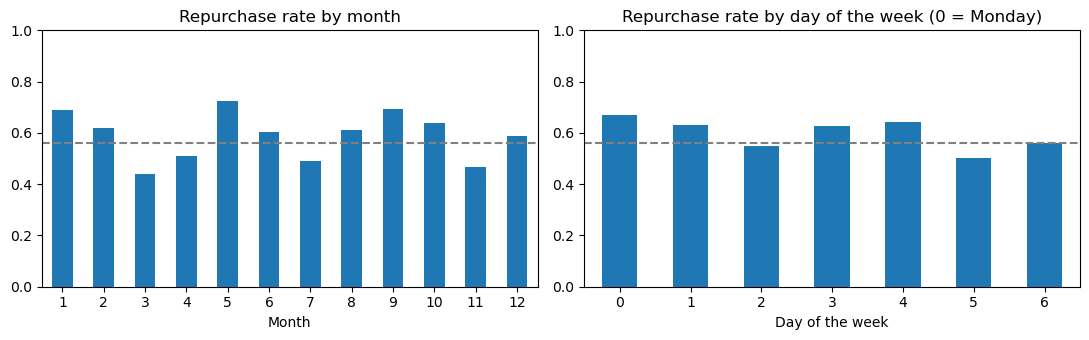

In [333]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
overall = train_clean[TARGET].mean()

by_month["rate"].plot(kind="bar", ax=axes[0], color="tab:blue", rot=0)
axes[0].set_title("Repurchase rate by month")
axes[0].set_xlabel("Month")

by_dow["rate"].plot(kind="bar", ax=axes[1], color="tab:blue", rot=0)
axes[1].set_title("Repurchase rate by day of the week (0 = Monday)")
axes[1].set_xlabel("Day of the week")

for ax in axes:
    ax.axhline(overall, color="gray", linestyle="--")   # overall rate
    ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

**What we see:**
- **Month:** the rate goes from about 44% (March) to about 72% (May). With about 200 or more purchases in every month, differences this big are more than chance, so the time of the year seems to matter.
- **Day of the week:** Saturday concentrates about half of all purchases and has a lower rate (about 50%) than Monday, Tuesday and Friday (63% to 67%). Wednesday and Thursday have very few purchases.

Do train and test look alike in this respect? We also check the day of the month, which we expect to have no effect.

In [334]:
dow_share = pd.DataFrame({
    "train_%": (dates_train.dt.dayofweek.value_counts(normalize=True).sort_index() * 100).round(1),
    "test_%":  (dates_test.dt.dayofweek.value_counts(normalize=True).sort_index() * 100).round(1),
}).fillna(0)
print("Share of purchases by day of the week:")
print(dow_share.T.to_string())

# Day of the month, in four blocks
week_of_month = pd.cut(dates_train.dt.day, [0, 7, 14, 21, 31])
print("\nRepurchase rate by block of days of the month:")
print(train_clean.groupby(week_of_month, observed=True)[TARGET].mean().round(3).to_string())

Share of purchases by day of the week:
purchase_date    0     1    2    3     4     5     6
train_%        9.7  10.6  1.3  0.4  12.5  49.7  15.8
test_%         9.6  11.4  3.5  0.0  12.8  49.6  13.1

Repurchase rate by block of days of the month:
purchase_date
(0, 7]      0.550
(7, 14]     0.571
(14, 21]    0.571
(21, 31]    0.551


**What we see:** the weekday pattern is very similar in train and test (Saturday is about half of the purchases in both), and the day of the month makes no difference (about 55% to 57% in every block), so we ignore it.

#### Decisions

| Feature | Decision | Why |
|---|---|---|
| Month | two columns, `purchase_month_sin` and `purchase_month_cos` | December and January are neighbours, but as numbers 12 and 1 are far apart. Sine and cosine put the 12 months on a circle, so the neighbours stay close |
| Day of the week | one column with the name of the day (`dow_0` ... `dow_6`), turned into categories in step 2.5 | the days have no real order, and Saturday behaves differently from the rest |
| Year | **not used** | train ends in 2025 and test goes to 2026: the model would see year values it has never seen, and could not learn what they mean |
| Day of the month | not used | no effect |

This is a **fixed rule** (no number is learned from the data), so we can apply it now to train and test.

In [335]:
def add_date_features(df):
    """Fixed rule: month on a circle (sin/cos) and day of the week as a name. Returns a copy."""
    df = df.copy()
    dt = pd.to_datetime(df[date_col])
    month = dt.dt.month
    df["purchase_month_sin"] = np.sin(2 * np.pi * month / 12)
    df["purchase_month_cos"] = np.cos(2 * np.pi * month / 12)
    df["purchase_dayofweek"] = "dow_" + dt.dt.dayofweek.astype(str)
    return df

train_clean = add_date_features(train_clean)
test_clean = add_date_features(test_clean)

print(train_clean[[date_col, "purchase_month_sin", "purchase_month_cos", "purchase_dayofweek"]].head(4).to_string())

  purchase_date  purchase_month_sin  purchase_month_cos purchase_dayofweek
0    2024-10-29           -0.866025        5.000000e-01              dow_1
1    2017-07-08           -0.500000       -8.660254e-01              dow_5
2    2019-03-19            1.000000        6.123234e-17              dow_1
3    2018-11-10           -0.500000        8.660254e-01              dow_5


### 2.5 Categorical variables

Models need numbers, so every text category has to be converted. Before choosing how, we check whether each categorical column is **reliable**, comparing train with test:

- how many categories each one has;
- how much of the data is in a single category (a column that is >99% one category carries almost no information);
- how many test rows have a category that never appears in train (the model cannot know what to do with those).

In [336]:
rows = []
for c in cat_cols:
    seen_in_train = set(train_clean[c].dropna().unique())
    in_test = test_clean[c].dropna()
    rows.append({
        "column": c,
        "n_cat_train": train_clean[c].nunique(),
        "n_cat_test": test_clean[c].nunique(),
        "top_cat_%_train": round(train_clean[c].value_counts(normalize=True).iloc[0] * 100, 1),
        "top_cat_%_test": round(test_clean[c].value_counts(normalize=True).iloc[0] * 100, 1),
        "test_rows_unseen_%": round((~in_test.isin(seen_in_train)).sum() / len(test_clean) * 100, 1),
    })
print(pd.DataFrame(rows).to_string(index=False))

          column  n_cat_train  n_cat_test  top_cat_%_train  top_cat_%_test  test_rows_unseen_%
    payment_type            9          11             72.8            67.4                 0.3
     salesperson            9           3             64.6            49.6                 0.0
 commercial_zone            5           5             96.8            70.1                21.2
transport_method           80          29             17.8            22.3                 6.4
       warehouse            2           2             99.7            99.3                 0.7
 document_series            3           1             42.3           100.0                 0.0


**What we see:**
- `commercial_zone`: train is 97% one zone, but the test set has a very different mix, and **about 21% of the test rows are in zones that never appear in train**. Whatever the model learned about zones would not transfer to test.
- `document_series`: the test set has **only one** series. In the EDA we saw that in train the three series all have the same repurchase rate (about 56%), so it carries no signal.
- `warehouse`: more than 99% of the rows are in one warehouse, in both train and test.
- `payment_type`, `salesperson` and `transport_method` are reliable enough (at most 6% of the test rows have a category never seen in train) and we saw in the EDA that `payment_type` and `salesperson` are informative.

**Decision:** `commercial_zone`, `document_series` and `warehouse` **leave the model**. This is a data-quality decision (unstable or almost constant columns); in section 3 we will confirm it with a feature-selection method.

`transport_method` still has a problem: **about 80 categories**. Let's see how many of them are really used.

In [337]:
counts = train_clean["transport_method"].fillna("missing").value_counts()
min_rows = 0.01 * len(train_clean)      # 1% of the training rows

print("Categories in train (including 'missing'):", len(counts))
print(f"Categories with at least 1% of the rows ({round(min_rows)} rows):", int((counts >= min_rows).sum()))
print("Share of the rows covered by those:", round(counts[counts >= min_rows].sum() / counts.sum() * 100, 1), "%")

# A small demonstration of the grouping. The list of frequent categories is learned ONLY from train
frequent = counts[counts >= min_rows].index

def group_rare(column, frequent):
    """Keeps the frequent categories and renames all the others (rare, or never seen in train) as 'infrequent'."""
    column = column.fillna("missing")
    return column.where(column.isin(frequent), "infrequent")

train_grouped = group_rare(train_clean["transport_method"], frequent)
test_grouped = group_rare(test_clean["transport_method"], frequent)

print("\nCategories grouped into one 'infrequent' column:", len(counts) - len(frequent))
print("Columns created for transport_method:", len(frequent) + 1)
print("Share of test rows in the 'infrequent' column:", round((test_grouped == "infrequent").mean() * 100, 1), "%")

Categories in train (including 'missing'): 81
Categories with at least 1% of the rows (65 rows): 22
Share of the rows covered by those: 90.8 %

Categories grouped into one 'infrequent' column: 59
Columns created for transport_method: 23
Share of test rows in the 'infrequent' column: 15.0 %


**What we see:** there are 81 categories (80 real ones plus `"missing"`), but only 22 of them have at least 1% of the rows, and those 22 cover about 91% of the purchases. The other 59 are very rare and end up together in one `infrequent` column. In the test set, about 15% of the rows fall into that column: some of them (about 6%) have categories that never appear in train, and the rest have categories that are rare in train.

#### Decision: how to encode

For `payment_type`, `salesperson`, `transport_method` and the day of the week (and the regions that come from `clientes.csv`, next step) we use:

1. **Missing values become a category** called `"missing"` (decided in step 2.3).
2. **One-hot encoding with grouping of rare categories**: one 0/1 column per category, but any category with **less than 1% of the training rows** is merged into a single `infrequent` column. Categories that **appear only in test** also go to that column.

Why this and not the alternatives?
- *Label encoding* (1, 2, 3, ...) would invent an order that does not exist, which misleads linear models.
- *Target encoding* (replace each category by its repurchase rate) uses the target, so it can leak information unless it is done with great care inside cross-validation. We prefer to avoid that risk in this simple pipeline.
- *One column per category for all 80 values* would create dozens of columns with only a handful of 1s each, which is noise.

The 1% threshold is **learned from the training set** (which categories are rare), so this encoder is a **fitted operation**: it goes into the `Preprocessor` of step 2.9.

### 2.6 The optional `clientes.csv` table

`clientes.csv` has one row per customer (1143 customers) with information about where the customer is and since when they are a customer. It can be joined to the purchases through `customer_id`.

Is it worth using? First, an overview of each column: how many distinct values it has and how much is missing.

In [338]:
print("Rows:", len(clientes), "| customer_id is unique:", clientes["customer_id"].is_unique)

overview = pd.DataFrame({
    "n_unique": clientes.nunique(),
    "%_missing": (clientes.isna().mean() * 100).round(1),
})
overview["decision"] = pd.Series({
    "customer_id": "join key",
    "country_or_region": "KEEP (categorical)",
    "commercial_region": "KEEP (categorical)",
    "island": "KEEP (categorical; missing is its own category)",
    "municipality": "drop: 183 categories",
    "city": "drop: 417 categories, half missing",
    "postal_area": "drop: 271 categories",
    "postal_code": "drop: 828 categories",
    "street": "drop: 511 categories, half missing",
    "address": "drop: almost one per customer (identifier-like)",
    "customer_type": "drop: 100% missing",
    "company_name": "drop: almost one per customer (identifier-like)",
    "customer_since_year": "drop: redundant (see below)",
})
print(overview.to_string())

Rows: 1143 | customer_id is unique: True
                     n_unique  %_missing                                         decision
customer_id              1143        0.0                                         join key
country_or_region          11        0.0                               KEEP (categorical)
commercial_region          37       10.0                               KEEP (categorical)
island                     10       50.6  KEEP (categorical; missing is its own category)
municipality              183       13.9                             drop: 183 categories
city                      417       47.8               drop: 417 categories, half missing
postal_area               271        6.2                             drop: 271 categories
postal_code               828       14.9                             drop: 828 categories
street                    511       52.3               drop: 511 categories, half missing
address                  1120        0.5  drop: almost one 

**What we see:**
- The columns form a **geographic hierarchy** (country > region > island > municipality > city > postal area > postal code > street > address). The more detailed levels have hundreds of categories, many gaps and very few purchases each, so a model cannot learn anything reliable from them. We keep only the three coarsest levels.
- `address` and `company_name` are almost unique per customer. They work as **identifiers**, not as characteristics: we drop them. `customer_type` is empty.
- `customer_since_year` could give the age of the customer at the time of the purchase. Let's check if that adds something that `customer_tenure_days` (already in `train.csv`) does not have.

In [339]:
def spearman(x, y):
    """Spearman correlation = Pearson correlation of the ranks. Pairs with a missing value are ignored.
    (We compute it by hand because pandas needs the extra library scipy for method="spearman".)"""
    pair = pd.concat([x, y], axis=1).dropna()
    return pair.iloc[:, 0].rank().corr(pair.iloc[:, 1].rank())

tmp = train_clean[["customer_id", date_col, "customer_tenure_days"]].merge(
    clientes[["customer_id", "customer_since_year"]], on="customer_id", how="left")
customer_age_years = pd.to_datetime(tmp[date_col]).dt.year - tmp["customer_since_year"]

print("Negative ages (purchase before the customer existed):", int((customer_age_years < 0).sum()))
print("Spearman correlation: customer age in years vs customer_tenure_days:",
      round(spearman(customer_age_years, tmp["customer_tenure_days"]), 3))

Negative ages (purchase before the customer existed): 0
Spearman correlation: customer age in years vs customer_tenure_days: 0.917


**What we see:** the age computed from `customer_since_year` has a correlation of about 0.92 with `customer_tenure_days`, which is the same information in different units. We drop `customer_since_year`.

Next, we check that the join is safe: does every customer of train **and** test exist in `clientes.csv`?

In [340]:
for name, df in [("train", train_clean), ("test", test_clean)]:
    print(f"{name}: customers not found in clientes.csv =", int((~df["customer_id"].isin(clientes["customer_id"])).sum()))

train: customers not found in clientes.csv = 0
test: customers not found in clientes.csv = 0


**What we see:** all customers are found, in both tables. We use a **left join** (every purchase keeps its row, and gets the customer's information added). We add two safety checks to the function: `validate="many_to_one"` makes pandas fail if `clientes.csv` had two rows for the same customer (which would duplicate purchases), and the `assert` checks that the number of rows did not change.

This join is a **fixed rule**: it adds customer characteristics that exist for every customer, and does not learn anything from `test.csv`.

In [341]:
clientes_keep = ["country_or_region", "commercial_region", "island"]

def add_customer_features(df, clientes):
    """Left join with the three geographic columns of clientes.csv. The number of rows must not change."""
    out = df.merge(clientes[["customer_id"] + clientes_keep], on="customer_id", how="left", validate="many_to_one")
    assert len(out) == len(df), "The join changed the number of rows"
    return out

train_clean = add_customer_features(train_clean, clientes)
test_clean = add_customer_features(test_clean, clientes)

print("train_clean:", train_clean.shape, "| test_clean:", test_clean.shape)
print("\nMissing in the new columns (train %):")
print((train_clean[clientes_keep].isna().mean() * 100).round(1).to_string())

train_clean: (6469, 46) | test_clean: (986, 45)

Missing in the new columns (train %):
country_or_region     0.0
commercial_region     0.5
island               33.8


Last check: are the kept columns related to the target, or are we adding noise?

In [342]:
for c in clientes_keep:
    g = (train_clean.assign(**{c: train_clean[c].fillna("missing")})
                    .groupby(c)[TARGET].agg(rate="mean", n="size").round(3)
                    .sort_values("n", ascending=False))
    print(f"--- {c} ({len(g)} categories); the 5 most frequent ---")
    print(g.head(5).to_string())
    print()

--- country_or_region (7 categories); the 5 most frequent ---
                                          rate     n
country_or_region                                   
Country CT10: Land of The Final Version  0.566  6256
Country CT5: Land of The Final Version   0.392   194
Country CT6: Land of The Final Version   0.500     8
Country CT7: Land of The Final Version   0.375     8
Country CT4: Land of The Final Version   0.000     1

--- commercial_region (33 categories); the 5 most frequent ---
                                 rate     n
commercial_region                          
Region RG17: We Will See Later  0.519  4069
Region RG23: We Will See Later  0.827   560
Region RG18: We Will See Later  0.621   364
Region RG24: We Will See Later  0.944   232
Region RG29: We Will See Later  0.507   211

--- island (11 categories); the 5 most frequent ---
                                    rate     n
island                                        
missing                            0.641  2189
I

**What we see:**
- `commercial_region`: the rate goes from about 52% in the biggest region to 83% and 94% in two others. This is a **strong signal**.
- `island`: purchases of customers with **no island** (a third of the rows) have a higher rate (about 64%) than the rest (50% to 57%), so "missing" is itself informative and the category `"missing"` keeps that signal.
- `country_or_region`: one country has 97% of the purchases, but another (with ~190 purchases) has a lower rate (about 39% vs 57%).

**Decision:** integrate `clientes.csv` with a left join on `customer_id`, keeping `country_or_region`, `commercial_region` and `island`, which are encoded as in step 2.5.

### 2.7 New features

The columns we received are mostly raw counts and totals. A model often learns better from **ratios** that express an idea directly. We propose nine candidates, all built **only from columns of the same row** (so they are fixed rules and cannot leak anything from test):

| Candidate | Idea |
|---|---|
| `purchase_rate_per_year` | how often the customer buys (earlier purchases per year of customer life) |
| `discount_rate` | discounts as a share of the gross total |
| `recent_spend_share` | share of the last-year spending that happened in the last 90 days |
| `recent_activity_ratio` | share of the last-year purchases that happened in the last 90 days |
| `overdue_ratio` | days since the previous purchase divided by the customer's usual gap: is the customer late compared to their own rhythm? |
| `avg_spend_per_purchase_365d` | average value of a purchase in the last year |
| `value_vs_usual` | value of this purchase compared with the customer's average |
| `tax_rate` | tax as a share of the net total |
| `has_shipping` | whether there is a shipping charge |

Dividing can create problems (division by zero gives infinity), so we use a safe division that returns `NaN` when the denominator is missing or not positive. Those `NaN` are handled later by the median imputation, like all the others.

In [343]:
def safe_divide(num, den):
    """num / den, but NaN where den is missing or not positive (avoids infinity and division by zero)."""
    return num / den.where(den > 0)

d = train_clean
candidates = pd.DataFrame({
    "purchase_rate_per_year":      safe_divide(d["prior_purchase_count"], d["customer_tenure_days"]) * 365,
    "discount_rate":               safe_divide(d["Total Desc_ Linha"] + d["Total Desc_ Global"], d["Total Bruto"]),
    "recent_spend_share":          safe_divide(d["spend_90d"], d["spend_365d"]),
    "recent_activity_ratio":       safe_divide(d["purchase_count_90d"], d["purchase_count_365d"]),
    "overdue_ratio":               safe_divide(d["days_since_previous_purchase"], d["prior_mean_gap_days"]),
    "avg_spend_per_purchase_365d": safe_divide(d["spend_365d"], d["purchase_count_365d"]),
    "value_vs_usual":              safe_divide(d["Total a Pagar"], d["prior_mean_purchase_value"]),
    "tax_rate":                    safe_divide(d["Total Imp_"], d["Total Liquido"]),
    "has_shipping":                (d["Total Portes"] > 0).astype(int),
})

evaluation = pd.DataFrame({
    "spearman_with_target": candidates.apply(lambda col: spearman(col, d[TARGET])).round(3),
    "n_missing": candidates.isna().sum(),
})
print(evaluation.sort_values("spearman_with_target", key=abs, ascending=False).to_string())

# For comparison: the raw columns that feed the best ratios
print("\nFor comparison (raw columns):")
for c in ["prior_purchase_count", "customer_tenure_days", "purchase_count_90d", "purchase_count_365d", "spend_90d", "spend_365d"]:
    print(f"  {c:22s} {spearman(d[c], d[TARGET]):+.3f}")

                             spearman_with_target  n_missing
purchase_rate_per_year                      0.423        603
discount_rate                               0.218          0
recent_spend_share                          0.190       1035
recent_activity_ratio                       0.177        843
avg_spend_per_purchase_365d                 0.084       1035
overdue_ratio                              -0.056       1438
has_shipping                                0.019          0
value_vs_usual                             -0.018        829
tax_rate                                    0.016          0

For comparison (raw columns):
  prior_purchase_count   +0.346
  customer_tenure_days   +0.120
  purchase_count_90d     +0.393
  purchase_count_365d    +0.437
  spend_90d              +0.359
  spend_365d             +0.388


**What we see:**
- `purchase_rate_per_year` has a correlation of about +0.42 with the target, much higher than either column it comes from (`prior_purchase_count` about +0.35, `customer_tenure_days` about +0.12). Combining them created **new information**.
- `discount_rate` (about +0.22), `recent_spend_share` (about +0.19) and `recent_activity_ratio` (about +0.18) are also clearly related to the target.
- `overdue_ratio` has a weak monotonic correlation (about -0.06), but it measures something no single column can ("is this customer late?"), and a model can use it in more complex ways. We keep it and let section 3 decide if it earns its place.
- `tax_rate` is almost constant (about 23% for nearly every row), `value_vs_usual` and `has_shipping` are close to 0, and `avg_spend_per_purchase_365d` (about +0.08) adds little to what its components already say. We **do not create** these four.

**Decision:** we keep `purchase_rate_per_year`, `discount_rate`, `recent_spend_share`, `recent_activity_ratio` and `overdue_ratio`.

(The missing values of `purchase_rate_per_year` are the first purchases: with no history, the customer life is 0 days and the rate does not exist. The flag `is_first_purchase` already marks them.)

In [344]:
def add_new_features(df):
    """Fixed rule: ratios built only with columns of the same row. Returns a copy."""
    df = df.copy()
    df["purchase_rate_per_year"] = safe_divide(df["prior_purchase_count"], df["customer_tenure_days"]) * 365
    df["discount_rate"] = safe_divide(df["Total Desc_ Linha"] + df["Total Desc_ Global"], df["Total Bruto"])
    df["recent_spend_share"] = safe_divide(df["spend_90d"], df["spend_365d"])
    df["recent_activity_ratio"] = safe_divide(df["purchase_count_90d"], df["purchase_count_365d"])
    df["overdue_ratio"] = safe_divide(df["days_since_previous_purchase"], df["prior_mean_gap_days"])
    return df

new_feature_cols = ["purchase_rate_per_year", "discount_rate", "recent_spend_share",
                    "recent_activity_ratio", "overdue_ratio"]

train_clean = add_new_features(train_clean)
test_clean = add_new_features(test_clean)

# Safety checks: no infinity, and see how many NaN each new feature has
for df in [train_clean, test_clean]:
    assert not np.isinf(df[new_feature_cols].to_numpy(dtype=float)).any()
print("Missing values in the new features:")
print(pd.DataFrame({"train": train_clean[new_feature_cols].isna().sum(),
                    "test": test_clean[new_feature_cols].isna().sum()}).to_string())

Missing values in the new features:
                        train  test
purchase_rate_per_year    603    22
discount_rate               0     0
recent_spend_share       1035    92
recent_activity_ratio     843    59
overdue_ratio            1438   109


### 2.8 Scaling

Variables have very different scales: `prior_purchase_count` is a small number, while `spend_365d` goes into the hundreds of thousands. Some models are sensitive to that (logistic regression, k-nearest neighbours, SVM, neural networks): the big-number variables would dominate. Tree-based models do not care, but scaling does not harm them either, so **one pipeline works for all models**.

Two questions: **which variables** need it, and **how**.

In the EDA we saw that most of the numerical variables are **very skewed** (a few huge values and many small ones). If we only standardise them, the huge values still dominate. The usual solution is to apply a logarithm first.

In [345]:
binary_cols = ["is_first_purchase"]                                   # already 0/1: not scaled
engineered_cols = new_feature_cols + ["purchase_month_sin", "purchase_month_cos"]
numeric_model_cols = num_cols + engineered_cols

# log(1 + x) needs values >= 0. We check it, otherwise the logarithm would be impossible
print("Smallest value among the numerical columns:", float(train_clean[num_cols + new_feature_cols].min().min()))

# Skewness: 0 = symmetric; above 1 = strongly skewed to the right
skewness = train_clean[numeric_model_cols].skew().sort_values(ascending=False)
skewed_cols = skewness[skewness > 1].index.tolist()
regular_cols = [c for c in numeric_model_cols if c not in skewed_cols]

print(f"\nSkewed (> 1): {len(skewed_cols)} columns | Not skewed: {len(regular_cols)} columns")
print("Not skewed:", regular_cols)

# Effect of log(1 + x) on the 6 most skewed columns
top = skewness.head(6).index
print("\nSkewness before and after log(1 + x):")
print(pd.DataFrame({"before": skewness[top], "after_log1p": np.log1p(train_clean[top]).skew()}).round(2).to_string())

Smallest value among the numerical columns: 0.0

Skewed (> 1): 32 columns | Not skewed: 3 columns
Not skewed: ['customer_tenure_days', 'purchase_month_sin', 'purchase_month_cos']

Skewness before and after log(1 + x):
                           before  after_log1p
overdue_ratio               43.66         1.99
Total Desc_ Global          27.46         9.28
prior_max_purchase_value    21.34        -0.44
prior_mean_purchase_value   21.20        -0.29
Total Portes                19.55         2.27
spend_365d                  18.55        -1.45


**What we see:** the minimum is 0, so the logarithm is always possible (this is also thanks to step 2.2, which removed the negative values). For most columns the logarithm removes the skewness (for example `prior_max_purchase_value`, from 21 to about -0.4). It helps less for columns that are mostly zeros: `Total Desc_ Global` is 98% zeros, so it only goes from 27 to 9, because no logarithm can fix a column that is almost all zeros. Section 3 will probably drop it.

**Decision:**

| Group | Columns | Treatment |
|---|---|---|
| Skewed numerical (skewness > 1) | 32 of the 35 numerical columns, including all the new ratios | median imputation, then `log(1 + x)`, then standardisation |
| Other numerical | `customer_tenure_days`, `purchase_month_sin`, `purchase_month_cos` | median imputation, then standardisation |
| Flag | `is_first_purchase` | none (already 0/1) |
| Categorical (one-hot) | encoded as in step 2.5 | none (the columns are 0/1) |

Why standardisation (subtract the mean and divide by the standard deviation, so that each column ends with mean 0 and standard deviation 1) and not a robust scaler (based on the median and the quartiles) or min-max scaling (between 0 and 1)? After the logarithm the extreme values are already tamed, so a robust scaler is not needed, and min-max scaling is very sensitive to the minimum and maximum, which are the least reliable values.

The list of skewed columns was decided here by looking at the **training set only**. The mean and the standard deviation used by the scaler are also learned from the training set only: that happens inside the `Preprocessor` (next step).

### 2.9 Everything in a single reproducible Preprocessor

Now we join all the steps. The structure has two layers:

1. **Fixed rules** (functions we wrote): `fix_anomalies`, `add_first_purchase_flag`, `add_date_features`, `add_customer_features`, `add_new_features`. The same function is applied to train and test. We put them in a single function, `prepare_features`.
2. **Fitted operations** (a `Preprocessor` class that we write ourselves): median imputation, logarithm, standardisation and one-hot encoding. It is **fitted on train only** (`fit`) and then only **applied** to test (`transform`).

First, the function that applies the fixed rules, in the same order as before. We start from the **raw** tables and we check that we get exactly the same result as in the step-by-step version, to confirm that everything is reproducible.

In [346]:
def prepare_features(df):
    """All the fixed rules, in order. The same function is used for train and test."""
    df = fix_anomalies(df)
    df = add_first_purchase_flag(df)
    df = add_date_features(df)
    df = add_customer_features(df, clientes)
    df = add_new_features(df)
    return df

# Start again from the RAW tables
train_raw = train.loc[~empty_mask_train].reset_index(drop=True)      # step 2.1 (train only)
train_prepared = prepare_features(train_raw)
test_prepared = prepare_features(test)

# Reproducibility check: same result as the step-by-step version
pd.testing.assert_frame_equal(train_prepared, train_clean)
pd.testing.assert_frame_equal(test_prepared, test_clean)
print("OK: the function reproduces the step-by-step result exactly.")
print("train_prepared:", train_prepared.shape, "| test_prepared:", test_prepared.shape)

OK: the function reproduces the step-by-step result exactly.
train_prepared: (6469, 51) | test_prepared: (986, 50)


Now we separate what the model will receive:

- `X_train` / `X_test`: the table of features;
- `y_train`: the target;
- `test_ids`: the `ID` of the test rows, **unchanged**, to build the submission file;
- `dates_train`: the date of each training purchase. It is **not a feature**, but we need it in section 4 to validate the model over time.

In [347]:
y_train = train_prepared[TARGET]
test_ids = test_prepared["ID"]
dates_train = pd.to_datetime(train_prepared[date_col])

X_train = train_prepared.drop(columns=[TARGET])
X_test = test_prepared.copy()

cat_model_cols = ["payment_type", "salesperson", "transport_method",
                  "commercial_region", "island", "country_or_region", "purchase_dayofweek"]
used_cols = skewed_cols + regular_cols + binary_cols + cat_model_cols

print("Columns that go into the model:", len(used_cols))
print("Columns that are left out:")
print(sorted(set(X_train.columns) - set(used_cols)))

Columns that go into the model: 43
Columns that are left out:
['ID', 'commercial_zone', 'customer_id', 'document_series', 'purchase_date', 'random_noise', 'warehouse']


**What we see:** the columns left out are the identifiers (`ID`, `customer_id`), `random_noise`, the three unreliable categorical columns of step 2.5 (`commercial_zone`, `document_series`, `warehouse`), and `purchase_date` (the text date, already replaced by the sine, cosine and day-of-week columns).

The identifiers and `random_noise` are left out **provisionally**: the full justification and the check with a feature-selection method are in section 3.

Now we write the `Preprocessor`. It is a small class that we build ourselves with only `pandas` and `numpy`, and it works like the transformers of scikit-learn, with two methods:

- `fit(X_train)`: **learns** from the training table (medians, means, standard deviations and the list of frequent categories) and stores them;
- `transform(X)`: **applies** what was stored to any table. It never looks at the values of the table it receives to decide anything.

Each part of the code has a comment that says which of the earlier decisions it implements.

In [348]:
class Preprocessor:
    """Learns from a training table (fit) and then applies what it learned to any table (transform).

    What it learns (always from the table given to fit):
      - the median of every numerical column (to fill the gaps);
      - the mean and standard deviation of every numerical column, after the logarithm (to standardise);
      - which categories are frequent (at least `min_frequency` of the rows) in every categorical column.
    """

    def __init__(self, skewed_cols, regular_cols, binary_cols, cat_cols, min_frequency=0.01):
        self.skewed_cols = skewed_cols
        self.regular_cols = regular_cols
        self.binary_cols = binary_cols
        self.cat_cols = cat_cols
        self.min_frequency = min_frequency
        self.num_cols = skewed_cols + regular_cols

    def _numerical(self, X):
        """Step 2.3: fill the gaps with the learned medians. Step 2.8: logarithm on the skewed columns."""
        num = X[self.num_cols].fillna(self.medians_)
        num[self.skewed_cols] = np.log1p(num[self.skewed_cols])
        return num

    def fit(self, X):
        # 1. Medians (the gaps are ignored when computing them)
        self.medians_ = X[self.num_cols].median()

        # 2. Mean and standard deviation, after filling the gaps and applying the logarithm
        num = self._numerical(X)
        self.means_ = num.mean()
        self.stds_ = num.std(ddof=0).replace(0, 1)      # a column with no variation is not divided by zero

        # 3. Frequent categories of each categorical column (step 2.5). The gaps count as the category "missing"
        self.categories_ = {}
        self.has_infrequent_ = {}
        for c in self.cat_cols:
            col = X[c].fillna("missing")
            counts = col.value_counts()
            frequent = counts[counts >= self.min_frequency * len(X)].index.tolist()
            self.categories_[c] = frequent
            self.has_infrequent_[c] = len(frequent) < len(counts)
        return self

    def transform(self, X):
        # Numerical: standardise with the mean and standard deviation learned in fit
        num = (self._numerical(X) - self.means_) / self.stds_

        parts = [num, X[self.binary_cols].astype(float)]       # flags are already 0/1: not scaled

        # Categorical: one 0/1 column per frequent category + one column for all the others
        # (this includes categories that were never seen in fit)
        for c in self.cat_cols:
            col = X[c].fillna("missing")
            dummies = {f"{c}_{cat}": (col == cat).astype(float) for cat in self.categories_[c]}
            if self.has_infrequent_[c]:
                dummies[f"{c}_infrequent"] = (~col.isin(self.categories_[c])).astype(float)
            parts.append(pd.DataFrame(dummies, index=X.index))

        return pd.concat(parts, axis=1)

    def fit_transform(self, X):
        return self.fit(X).transform(X)

preprocess = Preprocessor(skewed_cols, regular_cols, binary_cols, cat_model_cols, min_frequency=0.01)

Now the key moment. Look at the two lines below:

- `fit_transform(X_train)`: **learns** (medians, means, standard deviations, categories) from the **training set** and transforms it;
- `transform(X_test)`: only **applies** what was learned. It never looks at the test values to decide anything.

In [349]:
X_train_prep = preprocess.fit_transform(X_train)     # learns from TRAIN and transforms it
X_test_prep = preprocess.transform(X_test)           # only applies what was learned

print("X_train_prep:", X_train_prep.shape)
print("X_test_prep :", X_test_prep.shape)

X_train_prep: (6469, 105)
X_test_prep : (986, 105)


Now the checks that confirm that everything is correct:

In [350]:
# 1. No missing values left, and the same columns in train and test
assert X_train_prep.isna().sum().sum() == 0
assert X_test_prep.isna().sum().sum() == 0
assert list(X_train_prep.columns) == list(X_test_prep.columns)

# 2. Identifiers and noise did not get in
assert not {"ID", "customer_id", "random_noise"} & set(X_train_prep.columns)

# 3. Test rows: all of them are still there, in the same order
assert len(X_test_prep) == len(sample_sub) == len(test_ids)
assert (test_ids.to_numpy() == sample_sub["ID"].to_numpy()).all() or set(test_ids) == set(sample_sub["ID"])
print("Basic checks passed.")

# 4. Proof that the scaler learned from train only: train columns have mean 0 and std 1,
#    but test columns do NOT (if we had fitted on test, they would)
sample_cols = skewed_cols[:4]
check = pd.DataFrame({
    "train_mean": X_train_prep[sample_cols].mean(),
    "train_std":  X_train_prep[sample_cols].std(),
    "test_mean":  X_test_prep[sample_cols].mean(),
    "test_std":   X_test_prep[sample_cols].std(),
}).round(3)
print("\n", check.to_string())

# 5. Some of the values learned from the training set
print("\nMedians learned from train (examples):")
print(preprocess.medians_[["prior_mean_gap_days", "days_since_previous_purchase", "spend_365d"]].round(2).to_string())

# 6. Reproducibility: a fresh Preprocessor, fitted again, gives exactly the same result
preprocess_2 = Preprocessor(skewed_cols, regular_cols, binary_cols, cat_model_cols, min_frequency=0.01).fit(X_train)
pd.testing.assert_frame_equal(preprocess_2.transform(X_test), X_test_prep)
print("\nReproducibility check passed.")

Basic checks passed.

                            train_mean  train_std  test_mean  test_std
overdue_ratio                    -0.0        1.0     -0.087     0.913
Total Desc_ Global               -0.0        1.0      0.118     1.422
prior_max_purchase_value         -0.0        1.0      0.498     0.962
prior_mean_purchase_value         0.0        1.0      0.381     1.005

Medians learned from train (examples):
prior_mean_gap_days               68.61
days_since_previous_purchase      57.00
spend_365d                      2426.60

Reproducibility check passed.


**What we see:** the training columns have mean 0 and standard deviation 1 (the scaler was fitted on them), while the test columns do **not** (for example `prior_max_purchase_value` has a mean of about 0.5 in test). That is expected, and it is the proof that the test set did not take part in the fitting: it has its own distribution, and the scaler never looked at it. (It also shows that test purchases tend to have higher values than the training ones, one more sign of the difference between the two sets). Re-fitting a fresh `Preprocessor` gives the same numbers, so the result is reproducible.

How many columns does each group have?

In [351]:
groups = {
    "numerical (skewed)": skewed_cols,
    "numerical (other)": regular_cols,
    "flag": binary_cols,
}
for name, cols in groups.items():
    print(f"{name:20s} {len(cols):3d} columns")
for c in cat_model_cols:
    print(f"{'one-hot: ' + c:20s} {sum(col.startswith(c + '_') for col in X_train_prep.columns):3d} columns")
print("\nTotal:", X_train_prep.shape[1], "columns")

numerical (skewed)    32 columns
numerical (other)      3 columns
flag                   1 columns
one-hot: payment_type   6 columns
one-hot: salesperson   7 columns
one-hot: transport_method  23 columns
one-hot: commercial_region  12 columns
one-hot: island       11 columns
one-hot: country_or_region   3 columns
one-hot: purchase_dayofweek   7 columns

Total: 105 columns


In [352]:
# Save train_clean so Part 3 can use it
train_clean.to_csv("../hdata/train_clean.csv", index=False)